# Datenbereinigung der Mietinserate

**Input:** `data/data_processed/flatfox_rentals_zentralschweiz.csv` (aus `data_engineering_real_estate.ipynb`: zusammengeführte Erhebungen, Gemeindezuordnung, Gemeindeindikatoren)

**Output:**
- `data/data_processed/flatfox_rentals_clean.csv` – bereinigte Analysestichprobe
- `data/data_processed/flatfox_rentals_excluded.csv` – alle entfernten Inserate mit Grund (zur Dokumentation)

**Zielgrösse:** monatliche **Nettomiete** (gemäss Feasibility Study) und daraus die Nettomiete pro m².

Das Notebook folgt den sechs Pflichtschritten der Projektbeschreibung:

1. Fehlende Werte und Duplikate
2. Datentypen
3. Wertebereiche (Plausibilität)
4. Ausreisser
5. Anreicherung mit zusätzlichen Spalten
6. Format für die Analyse

Vorab wird die Stichprobe auf unmöblierte, unbefristete Mietwohnungen mit Monatspreis eingegrenzt, da die Forschungsfragen Wohnungen betreffen. Der Input enthält alle Inserate der Zentralschweiz (auch Kaufangebote, Gewerbe und Parkplätze). Sämtliche Filter nach Inseratsmerkmalen erfolgen in diesem Notebook.

In [43]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "data_processed"
INPUT_FILE = DATA_DIR / "flatfox_rentals_zentralschweiz.csv"
OUTPUT_FILE = DATA_DIR / "flatfox_rentals_clean.csv"
EXCLUDED_FILE = DATA_DIR / "flatfox_rentals_excluded.csv"
PLZ_FILE = PROJECT_DIR / "data" / "geodata" / "ortschaftenverzeichnis_plz.csv"

CENTRAL_CANTONS = ["LU", "UR", "SZ", "OW", "NW", "ZG"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv(INPUT_FILE, low_memory=False)
print(f"Eingelesen: {len(raw)} Inserate, {raw.shape[1]} Spalten")

Eingelesen: 2640 Inserate, 156 Spalten


In [44]:
excluded = []
log = [("Ausgangslage", len(raw))]


def exclude(df, mask, step, reason):
    # Entfernt Zeilen gemäss Maske und protokolliert sie.
    mask = mask.fillna(False)
    removed = df.loc[mask, ["pk", "gemeinde_name", "kanton_geo", "object_type", "surface_living", "number_of_rooms"]].copy()
    removed["step"] = step
    removed["reason"] = reason
    excluded.append(removed)
    kept = df.loc[~mask].copy()
    log.append((f"{step}: {reason}", len(kept)))
    print(f"{step} – {reason}: {mask.sum()} entfernt, {len(kept)} verbleibend")
    return kept

## Eingrenzung auf Mietwohnungen

Der Input enthält alle Inserate der Zentralschweiz. Für die Forschungsfragen sind nur Mietwohnungen relevant, die mit dem regulären Mietmarkt vergleichbar sind:

| Kriterium | Entfernt werden | Begründung |
|---|---|---|
| Angebotsart | Kaufangebote | Kaufpreise sind nicht mit Mieten vergleichbar |
| Objekttyp | Gewerbe, Parkplätze, WG-Zimmer, Häuser | nicht mit Wohnungen vergleichbar |
| Möblierung | möblierte Wohnungen (`is_furnished` oder Objekttyp `FURNISHED_FLAT`) | Miete enthält die Möblierung |
| Befristung | befristete Angebote (`is_temporary`) | oft Zwischenmiete mit Sonderpreisen |
| Preiseinheit | alles ausser Monatspreis | z. B. Jahrespreis pro m² bei Gewerbeflächen |
| Koordinaten | Inserate, deren Postleitzahl zu einem anderen Kanton gehört als die Koordinaten | Gemeinde und Gemeindeindikatoren wären falsch |

**Koordinatenprüfung:** Die Gemeinde wird in `data_engineering_real_estate.ipynb` aus den Koordinaten bestimmt. Einzelne Inserate haben Koordinaten, die nicht zur angegebenen Adresse passen (z. B. Adresse in Pratteln BL, Koordinaten in Luzern). Wir vergleichen deshalb den Kanton aus den Koordinaten mit den Kantonen der Postleitzahl gemäss dem amtlichen Ortschaftenverzeichnis von swisstopo (`data/geodata/ortschaftenverzeichnis_plz.csv`). Verglichen wird auf Ebene Kanton und nicht Gemeinde, weil Postleitzahlgebiete oft über Gemeindegrenzen hinausreichen. Inserate mit einer Postleitzahl, die im Verzeichnis fehlt (z. B. 6000 Luzern), werden nicht entfernt.

In [45]:
display(raw["object_type"].value_counts().rename("Anzahl").to_frame())

APARTMENT_TYPES = ["APARTMENT", "ATTIC_FLAT", "DUPLEX", "ROOF_FLAT", "STUDIO", "LOFT", "TERRACE_FLAT"]

# Kantone je Postleitzahl; eine Postleitzahl kann zu mehreren Kantonen gehören.
plz = pd.read_csv(PLZ_FILE, sep=";", encoding="utf-8-sig")
cantons_by_plz = plz.groupby("PLZ4")["Kantonskürzel"].agg(set)
listing_plz_cantons = pd.to_numeric(raw["zipcode"], errors="coerce").map(cantons_by_plz)
plz_mismatch = pd.Series(
    [isinstance(cantons, set) and canton not in cantons
     for canton, cantons in zip(raw["kanton_geo"], listing_plz_cantons)],
    index=raw.index,
)

df = exclude(raw, raw["offer_type"].ne("RENT"), "0 Eingrenzung", "kein Mietangebot (Kauf)")
df = exclude(df, ~df["object_type"].isin(APARTMENT_TYPES + ["FURNISHED_FLAT"]), "0 Eingrenzung", "keine Wohnung (Gewerbe, Parkplatz, WG-Zimmer, Haus)")
df = exclude(df, df["is_furnished"].eq(True) | df["object_type"].eq("FURNISHED_FLAT"), "0 Eingrenzung", "möbliert")
df = exclude(df, df["is_temporary"].eq(True), "0 Eingrenzung", "befristet")
df = exclude(df, df["price_unit"].ne("monthly"), "0 Eingrenzung", "kein Monatspreis")

display(df.loc[plz_mismatch.loc[df.index], ["pk", "street", "zipcode", "city", "gemeinde_name", "kanton_geo"]])
df = exclude(df, plz_mismatch.loc[df.index], "0 Eingrenzung", "Postleitzahl passt nicht zum Kanton der Koordinaten")

apartments = df.copy()

,Anzahl
object_type,
APARTMENT,980
OFFICE,387
SHARED_FLAT,273
GARAGE_SLOT,185
COMMERCIAL,155
FURNISHED_FLAT,123
OPEN_SLOT,107
SINGLE_HOUSE,67
SHOP,47


0 Eingrenzung – kein Mietangebot (Kauf): 164 entfernt, 2476 verbleibend
0 Eingrenzung – keine Wohnung (Gewerbe, Parkplatz, WG-Zimmer, Haus): 1382 entfernt, 1094 verbleibend
0 Eingrenzung – möbliert: 261 entfernt, 833 verbleibend
0 Eingrenzung – befristet: 7 entfernt, 826 verbleibend
0 Eingrenzung – kein Monatspreis: 0 entfernt, 826 verbleibend


,pk,street,zipcode,city,gemeinde_name,kanton_geo
783,86302188,Birchweidweg 5,8707,Uetikon am See,Freienbach,SZ
1405,86418686,Burgmatt 1,6402,Merlischachen,Baar,ZG
1880,86460257,Floraweg 2,4133,Pratteln,Luzern,LU
2230,86485100,Floraweg 2,4133,Pratteln,Luzern,LU
2569,86513955,Floraweg 2,4133,Pratteln,Luzern,LU


0 Eingrenzung – Postleitzahl passt nicht zum Kanton der Koordinaten: 5 entfernt, 821 verbleibend


## Fehlende Werte und Duplikate

### Nettomiete
Die Nettomiete ist nicht bei allen Inseraten direkt angegeben. Wo sie fehlt, aber Bruttomiete und Nebenkosten vorhanden sind, wird sie berechnet: **Nettomiete = Bruttomiete − Nebenkosten**. Inserate, bei denen sich keine Nettomiete bestimmen lässt, werden entfernt. Fehlende Werte werden nicht geschätzt, weil die Miete unsere Zielgrösse ist.

### Wohnfläche und Zimmerzahl
Ohne Wohnfläche lässt sich die Miete pro m² nicht berechnen, ohne Zimmerzahl fehlt eine Kontrollvariable der Analyse. Diese Inserate werden ebenfalls entfernt und nicht geschätzt.

In [46]:
key_columns = ["rent_net", "rent_gross", "rent_charges", "surface_living", "number_of_rooms",
               "floor", "year_built", "year_renovated", "price_display"]
missing = pd.DataFrame({
    "fehlend": df[key_columns].isna().sum(),
    "fehlend (%)": df[key_columns].isna().mean().mul(100).round(1),
})
missing

,fehlend,fehlend (%)
rent_net,327,39.8
rent_gross,162,19.7
rent_charges,253,30.8
surface_living,102,12.4
number_of_rooms,1,0.1
floor,160,19.5
year_built,459,55.9
year_renovated,633,77.1
price_display,7,0.9


In [47]:
df["rent_net_source"] = np.where(df["rent_net"].notna(), "angegeben", None)
derived = df["rent_net"].isna() & df["rent_gross"].notna() & df["rent_charges"].notna()
df.loc[derived, "rent_net"] = df.loc[derived, "rent_gross"] - df.loc[derived, "rent_charges"]
df.loc[derived, "rent_net_source"] = "berechnet (brutto − Nebenkosten)"

print(df["rent_net_source"].value_counts(dropna=False))

df = exclude(df, df["rent_net"].isna(), "1 Fehlende Werte", "keine Nettomiete bestimmbar")
df = exclude(df, df["surface_living"].isna(), "1 Fehlende Werte", "keine Wohnfläche")
df = exclude(df, df["number_of_rooms"].isna(), "1 Fehlende Werte", "keine Zimmerzahl")

rent_net_source
angegeben                           494
NaN                                 237
berechnet (brutto − Nebenkosten)     90
Name: count, dtype: int64
1 Fehlende Werte – keine Nettomiete bestimmbar: 237 entfernt, 584 verbleibend
1 Fehlende Werte – keine Wohnfläche: 53 entfernt, 531 verbleibend
1 Fehlende Werte – keine Zimmerzahl: 0 entfernt, 531 verbleibend


Wie stark die Stichprobe durch die Nettomiete pro Kanton schrumpft, ist wichtig für die Interpretation (besonders für Uri, Obwalden und Nidwalden):

In [48]:
before = apartments["kanton_geo"].value_counts()
after = df["kanton_geo"].value_counts()
pd.DataFrame({"Wohnungen": before, "mit Nettomiete": after}).reindex(CENTRAL_CANTONS).fillna(0).astype(int)

,Wohnungen,mit Nettomiete
kanton_geo,,
LU,581,375
UR,17,9
SZ,109,79
OW,18,10
NW,14,10
ZG,82,48


### Gemeindeindikatoren
Die Sozialhilfequote fehlt für einige kleine Gemeinden. Diese Inserate werden nicht entfernt, weil alle anderen Angaben vorhanden sind. In Analysen mit der Sozialhilfequote fallen sie automatisch weg.

In [49]:
indicator_columns = ["income_median_chf", "population_growth_pct", "population_density_productive",
                     "household_size_mean", "vacancy_rate_pct", "social_assistance_rate_pct",
                     "population_age65plus_pct", "employment_per_100_residents",
                     "new_dwellings_per_1000_residents", "single_family_buildings_pct",
                     "foreign_population_pct", "net_migration_per_1000_residents"]
df[indicator_columns].isna().sum().rename("fehlende Werte").to_frame()

,fehlende Werte
income_median_chf,0
population_growth_pct,0
population_density_productive,0
household_size_mean,0
vacancy_rate_pct,0
social_assistance_rate_pct,5
population_age65plus_pct,0
employment_per_100_residents,0
new_dwellings_per_1000_residents,0
single_family_buildings_pct,0


### Duplikate
Die Inserat-ID (`pk`) ist nach dem Zusammenführen bereits eindeutig. Dieselbe Wohnung kann aber unter einer neuen ID erneut inseriert werden. Als Duplikat gilt ein Inserat, wenn

- Gemeinde, Strasse, Fläche, Zimmerzahl und Stockwerk mit einem anderen Inserat übereinstimmen und
- das andere Inserat erst erscheint, nachdem dieses verschwunden ist.

Behalten wird jeweils das neueste Inserat, weil es den aktuellen Preis enthält. Die Miete gehört bewusst nicht zum Vergleich, damit auch Neuinserate mit geändertem Preis erkannt werden.

Waren zwei Inserate gleichzeitig online, handelt es sich um verschiedene Wohnungen (z. B. gleich geschnittene Wohnungen im selben Neubau). Sie bleiben beide erhalten. Inserate ohne Strasse oder mit dem Platzhalter "Auf Anfrage" werden nicht verglichen, weil Gemeinde, Fläche und Zimmerzahl allein keine Wohnung eindeutig bestimmen.

In [50]:
assert df["pk"].is_unique, "pk ist nicht eindeutig"

dup_key = ["gemeinde_bfs", "street", "surface_living", "number_of_rooms", "floor"]
df = df.sort_values(["first_seen_at", "pk"], kind="stable")

# "Auf Anfrage" ist ein Platzhalter und bestimmt keine Wohnung.
street_known = df["street"].notna() & df["street"].ne("Auf Anfrage")
known = df.loc[street_known]

# Duplikat: Die nächste Wiederholung derselben Wohnung erscheint erst, nachdem dieses Inserat verschwunden ist.
next_first_seen = known.groupby(dup_key, dropna=False)["first_seen_at"].shift(-1)
is_dup = next_first_seen.gt(known["last_seen_at"]).reindex(df.index, fill_value=False)

display(known[known.duplicated(subset=dup_key, keep=False)]
        .sort_values(dup_key + ["first_seen_at"])
        [["pk", "gemeinde_name", "street", "surface_living", "number_of_rooms", "floor", "rent_net", "first_seen_at", "last_seen_at"]]
        .assign(entfernt=lambda t: t.index.isin(is_dup[is_dup].index)))

df = exclude(df, is_dup, "1 Duplikate", "gleiche Wohnung unter neuer ID")

,pk,gemeinde_name,street,surface_living,number_of_rooms,floor,rent_net,first_seen_at,last_seen_at,entfernt
1821,86456070,Kriens,Schachenstrasse 45,77.0,4.5,1.0,1490.0,2026-10-18T12:14:52.635701Z,2026-10-22T15:35:15.050865Z,True
2159,86479687,Kriens,Schachenstrasse 45,77.0,4.5,1.0,1490.0,2026-10-24T08:49:29.632207Z,2026-10-24T09:39:01.857255Z,False
230,85820071,Luzern,Weinmarkt 11,71.0,2.5,5.0,2360.0,2026-10-18T12:14:52.635701Z,2026-10-24T09:39:01.857255Z,False
2139,86476892,Luzern,Weinmarkt 11,71.0,2.5,5.0,2360.0,2026-10-23T12:25:48.028947Z,2026-11-06T06:40:53.202825Z,False
1529,86428626,Ruswil,Wolhuserstrasse 13,141.0,4.5,2.0,2300.0,2026-10-18T12:14:52.635701Z,2026-10-18T19:11:16.940418Z,True
1972,86463610,Ruswil,Wolhuserstrasse 13,141.0,4.5,2.0,2300.0,2026-10-19T15:11:08.866230Z,2026-10-29T07:47:51.724442Z,True
2351,86497916,Ruswil,Wolhuserstrasse 13,141.0,4.5,2.0,2300.0,2026-10-30T19:03:47.670233Z,2026-11-06T06:40:53.202825Z,False
610,86225345,Hünenberg,Matten 14,122.0,4.5,1.0,3630.0,2026-10-18T12:14:52.635701Z,2026-10-29T07:47:51.724442Z,True
2393,86502034,Hünenberg,Matten 14,122.0,4.5,1.0,3530.0,2026-10-30T19:03:47.670233Z,2026-11-06T06:40:53.202825Z,False


1 Duplikate – gleiche Wohnung unter neuer ID: 4 entfernt, 527 verbleibend


## Datentypen

Beim Einlesen aus CSV erkennt pandas nicht alle Typen korrekt (z. B. Zeitstempel als Text, IDs als Kommazahl). Wir setzen sie explizit.

In [51]:
print("Vorher:")
check_columns = ["pk", "gemeinde_bfs", "number_of_rooms", "floor", "year_built", "first_seen_at",
                 "published", "is_furnished", "attribute_reported_lift", "kanton_geo", "object_type"]
display(df[check_columns].dtypes.rename("dtype").to_frame())

df["pk"] = df["pk"].astype("int64")
df["gemeinde_bfs"] = df["gemeinde_bfs"].astype("Int64")

for col in ["floor", "year_built", "year_renovated"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

for col in ["rent_net", "rent_gross", "rent_charges", "surface_living", "number_of_rooms"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("float64")

for col in ["first_seen_at", "last_seen_at"]:
    df[col] = pd.to_datetime(df[col], utc=True)
df["published"] = pd.to_datetime(df["published"], utc=True, format="ISO8601")

bool_columns = ["is_furnished", "is_temporary"] + [c for c in df.columns if c.startswith("attribute_reported_")]
for col in bool_columns:
    df[col] = df[col].astype("boolean")

for col in ["kanton_geo", "object_type", "rent_net_source"]:
    df[col] = df[col].astype("category")

print("Nachher:")
display(df[check_columns].dtypes.rename("dtype").to_frame())

Vorher:


,dtype
pk,int64
gemeinde_bfs,int64
number_of_rooms,float64
floor,float64
year_built,float64
first_seen_at,str
published,str
is_furnished,bool
attribute_reported_lift,bool
kanton_geo,str


Nachher:


,dtype
pk,int64
gemeinde_bfs,Int64
number_of_rooms,float64
floor,Int64
year_built,Int64
first_seen_at,"datetime64[us, UTC]"
published,"datetime64[us, UTC]"
is_furnished,boolean
attribute_reported_lift,boolean
kanton_geo,category


## Wertebereiche

Wir prüfen, ob die Werte in einem plausiblen Bereich liegen. Die Grenzen sind bewusst grosszügig gewählt; sie sollen nur offensichtliche Erfassungsfehler erkennen. Ungewöhnliche, aber mögliche Werte werden im nächsten Schritt (Ausreisser) behandelt.

| Variable | Plausibler Bereich | Begründung | Behandlung |
|---|---|---|---|
| Wohnfläche | ≥ 20 m² | Kleinere Einheiten sind Zimmer, keine Wohnungen | Inserat entfernen |
| Fläche pro Zimmer | ≥ 8 m² | Kleinere Werte deuten auf Fehleingabe hin | Inserat entfernen |
| Nettomiete | > 0 und > Nebenkosten | Nebenkosten höher als Miete ist unplausibel | Inserat entfernen |
| Zimmerzahl | 1–10 | | Inserat entfernen |
| Stockwerk | −1 bis 30 | Höchste Wohngebäude der Region haben < 30 Stockwerke; 99 ist ein Platzhalter | Wert auf fehlend setzen |
| Baujahr | 1500 bis 2027 | Altstadtgebäude bis Neubau in Planung | Wert auf fehlend setzen |
| Koordinaten | innerhalb der Zentralschweiz | wurde bereits bei der Gemeindezuordnung geprüft | – |

Bei Stockwerk und Baujahr setzen wir nur den Wert auf fehlend, weil diese Variablen nicht zentral sind und der Rest des Inserats brauchbar ist.

In [52]:
display(df[["surface_living", "number_of_rooms", "rent_net", "rent_charges", "floor", "year_built"]]
        .describe().T[["min", "25%", "50%", "75%", "max"]])

df = exclude(df, df["surface_living"] < 20, "3 Wertebereich", "Wohnfläche < 20 m²")
df = exclude(df, df["surface_living"] / df["number_of_rooms"] < 8, "3 Wertebereich", "Fläche pro Zimmer < 8 m²")
df = exclude(df, (df["rent_net"] <= 0) | (df["rent_charges"] >= df["rent_net"]), "3 Wertebereich", "Nettomiete ≤ 0 oder ≤ Nebenkosten")
df = exclude(df, ~df["number_of_rooms"].between(1, 10), "3 Wertebereich", "Zimmerzahl ausserhalb 1–10")

bad_floor = ~df["floor"].between(-1, 30) & df["floor"].notna()
bad_year = ~df["year_built"].between(1500, 2027) & df["year_built"].notna()
print(f"Stockwerk auf fehlend gesetzt: {bad_floor.sum()} (Werte: {sorted(df.loc[bad_floor, 'floor'].tolist())})")
print(f"Baujahr auf fehlend gesetzt: {bad_year.sum()}")
df.loc[bad_floor, "floor"] = pd.NA
df.loc[bad_year, "year_built"] = pd.NA

,min,25%,50%,75%,max
surface_living,10.0,66.0,85.0,106.0,440.0
number_of_rooms,1.0,2.5,3.5,4.5,8.0
rent_net,0.0,1555.0,1960.0,2455.0,9000.0
rent_charges,0.0,180.0,240.0,300.0,2900.0
floor,-1.0,1.0,2.0,3.0,99.0
year_built,0.0,1971.25,2012.0,2024.0,2027.0


3 Wertebereich – Wohnfläche < 20 m²: 4 entfernt, 523 verbleibend
3 Wertebereich – Fläche pro Zimmer < 8 m²: 0 entfernt, 523 verbleibend
3 Wertebereich – Nettomiete ≤ 0 oder ≤ Nebenkosten: 3 entfernt, 520 verbleibend
3 Wertebereich – Zimmerzahl ausserhalb 1–10: 0 entfernt, 520 verbleibend
Stockwerk auf fehlend gesetzt: 2 (Werte: [33, 99])
Baujahr auf fehlend gesetzt: 1


## Ausreisser

Für die Ausreisser betrachten wir die **Nettomiete pro m²**, weil sie Wohnungen unterschiedlicher Grösse vergleichbar macht.

**Methode:** Tukey-Regel (Werte unter Q1 − 1.5·IQR oder über Q3 + 1.5·IQR), angewendet auf den **Logarithmus** der Miete pro m². Mietpreise sind rechtsschief verteilt; ohne log-Transformation würden zu viele teure, aber echte Wohnungen als Ausreisser gelten.

**Behandlung:** Entfernen. Es sind nur wenige Inserate betroffen (siehe Tabelle). Am unteren Ende stehen sehr grosse Flächen zu tiefer Miete, was auf eine falsch erfasste Fläche hindeutet (z. B. inkl. Nebenräume). Am oberen Ende stehen Luxus- oder Kleinstwohnungen, die nicht zum regulären Mietwohnungsmarkt passen. Solche Extremwerte würden die Regression überproportional beeinflussen.

In [53]:
df["rent_net_per_m2"] = df["rent_net"] / df["surface_living"]
log_price = np.log(df["rent_net_per_m2"])

q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)
is_outlier = ~df["rent_net_per_m2"].between(lower, upper)

print(f"Grenzen: {lower:.1f} bis {upper:.1f} CHF/m² und Monat")
display(df.loc[is_outlier, ["pk", "gemeinde_name", "object_type", "number_of_rooms", "surface_living",
                            "rent_net", "rent_net_per_m2", "short_title"]].sort_values("rent_net_per_m2"))

Grenzen: 10.6 bis 54.7 CHF/m² und Monat


,pk,gemeinde_name,object_type,number_of_rooms,surface_living,rent_net,rent_net_per_m2,short_title
755,86287981,Triengen,APARTMENT,3.5,239.0,1690.0,7.071130,3 ½ rooms apartment
929,86344230,Feusisberg,APARTMENT,4.0,140.0,1000.0,7.142857,4 rooms apartment
815,86311690,Isenthal,APARTMENT,5.5,125.0,1000.0,8.000000,5 ½ rooms apartment
1784,86453812,Kriens,APARTMENT,3.5,118.0,6500.0,55.084746,3 ½ rooms apartment
2200,86482029,Baar,APARTMENT,5.5,160.0,8850.0,55.312500,5 ½ rooms apartment
952,86351028,Cham,APARTMENT,3.5,71.0,4000.0,56.338028,3 ½ rooms apartment
2282,86488842,Luzern,APARTMENT,1.5,25.0,1460.0,58.400000,1 ½ rooms apartment
168,85535596,Schwyz,APARTMENT,1.0,20.0,1180.0,59.000000,1 room apartment
1577,86431114,Küssnacht (SZ),APARTMENT,1.0,24.0,1500.0,62.500000,1 room apartment
1192,86391520,Zug,APARTMENT,3.5,88.0,6000.0,68.181818,3 ½ rooms apartment


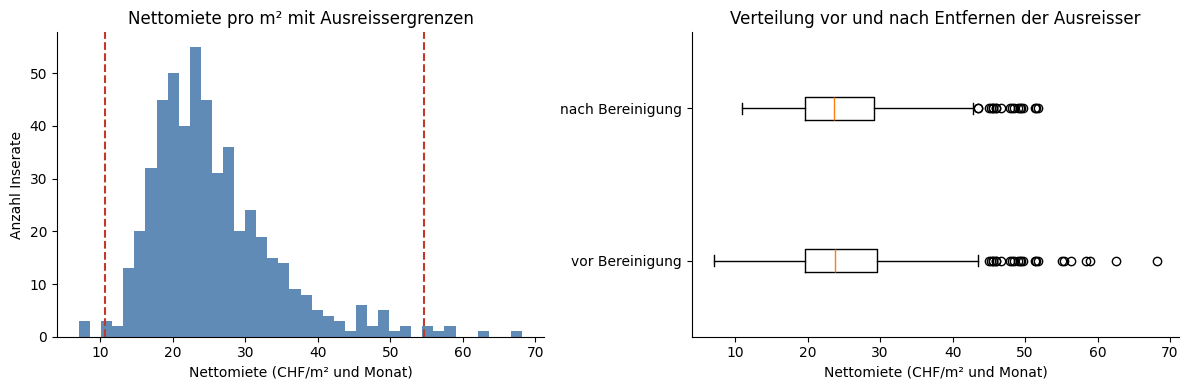

4 Ausreisser – Nettomiete/m² ausserhalb 10.6–54.7 CHF: 10 entfernt, 510 verbleibend


In [54]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["rent_net_per_m2"], bins=40, color="#3a6ea5", alpha=0.8)
for x in (lower, upper):
    axes[0].axvline(x, color="#c0392b", ls="--")
axes[0].set(title="Nettomiete pro m² mit Ausreissergrenzen", xlabel="Nettomiete (CHF/m² und Monat)", ylabel="Anzahl Inserate")

axes[1].boxplot([df["rent_net_per_m2"], df.loc[~is_outlier, "rent_net_per_m2"]], orientation="horizontal")
axes[1].set_yticks([1, 2], ["vor Bereinigung", "nach Bereinigung"])
axes[1].set(title="Verteilung vor und nach Entfernen der Ausreisser", xlabel="Nettomiete (CHF/m² und Monat)")

plt.tight_layout()
plt.show()

df = exclude(df, is_outlier, "4 Ausreisser", f"Nettomiete/m² ausserhalb {lower:.1f}–{upper:.1f} CHF")

*Hinweis zum Boxplot:* Der Boxplot verwendet die Tukey-Grenzen auf der normalen Skala und zeigt deshalb auch nach der Bereinigung noch einzelne Punkte über ca. 45 CHF/m². Auf der log-Skala, die wir für die Ausreisserregel verwenden, liegen diese Werte innerhalb der Grenzen. Es sind teure, aber plausible Wohnungen (v. a. Zug und Stadt Luzern).

## Anreicherung

Zusätzliche Spalten, die für die Analyse nützlich sind:

| Neue Spalte | Inhalt |
|---|---|
| `rent_net_per_m2` | Nettomiete pro m² und Monat (bereits in Schritt 4 erstellt) – Hauptzielgrösse |
| `rent_net_source` | ob die Nettomiete angegeben oder berechnet wurde (Schritt 1) |
| `charges_share_pct` | Anteil Nebenkosten an der Bruttomiete |
| `building_age` | Jahre seit Bau bzw. letzter Renovation |
| `room_class` | Zimmerkategorie (1–1.5, 2–2.5, 3–3.5, 4–4.5, 5+) für Gruppenvergleiche |
| `population_density_log` | log der Bevölkerungsdichte (die Dichte ist sehr schief verteilt) |
| `days_online` | Tage zwischen Veröffentlichung und letzter Sichtung (Hinweis auf Nachfrage) |

In [55]:
rent_gross_full = df["rent_gross"].fillna(df["rent_net"] + df["rent_charges"])
df["charges_share_pct"] = (df["rent_charges"] / rent_gross_full * 100).round(1)

last_year = df[["year_built", "year_renovated"]].max(axis=1)
df["building_age"] = (2026 - last_year).clip(lower=0).astype("Int64")

df["room_class"] = pd.cut(df["number_of_rooms"], bins=[0, 1.5, 2.5, 3.5, 4.5, 11],
                          labels=["1–1.5", "2–2.5", "3–3.5", "4–4.5", "5+"])

df["population_density_log"] = np.log(df["population_density_productive"])

df["days_online"] = (df["last_seen_at"] - df["published"]).dt.days

df[["rent_net_per_m2", "charges_share_pct", "building_age", "room_class", "population_density_log", "days_online"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rent_net_per_m2,510.0,NaN,NaN,NaN,25.211496,7.663116,11.0,19.677083,23.615079,29.154171,51.818182
charges_share_pct,497.0,NaN,NaN,NaN,10.61992,3.181959,0.0,8.5,10.1,12.3,28.9
building_age,340.0,<NA>,<NA>,<NA>,12.220588,17.286793,0.0,0.0,6.0,18.0,86.0
room_class,510,5,3–3.5,207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population_density_log,510.0,NaN,NaN,NaN,6.715951,1.12726,3.030134,5.806187,7.035709,8.021355,8.311988
days_online,510.0,NaN,NaN,NaN,37.462745,61.425291,0.0,6.25,17.0,42.75,548.0


## Format für die Analyse

Der Input hat über 150 Spalten (alle Felder der Flatfox-API). Für die Analyse behalten wir nur die benötigten Spalten in einer sinnvollen Reihenfolge: Identifikation > Miete > Wohnungsmerkmale > Lage > Gemeindeindikatoren > Erhebung. Die Zusammenführung mit den Gemeindeindikatoren ist bereits in `data_engineering_real_estate.ipynb` erfolgt.

In [56]:
FINAL_COLUMNS = [
    # Identifikation
    "pk", "source_url", "object_type",
    # Miete
    "rent_net", "rent_net_source", "rent_net_per_m2", "rent_charges", "rent_gross", "charges_share_pct",
    # Wohnungsmerkmale
    "surface_living", "number_of_rooms", "room_class", "floor", "year_built", "year_renovated", "building_age",
    "attribute_reported_balconygarden", "attribute_reported_lift", "attribute_reported_view",
    "attribute_reported_parkingspace", "attribute_reported_minergie",
    # Lage
    "latitude", "longitude", "gemeinde_bfs", "gemeinde_name", "kanton_geo",
    # Gemeindeindikatoren
    *indicator_columns, "population_density_log",
    # Erhebung
    "published", "first_seen_at", "last_seen_at", "scrape_count", "days_online",
]

clean = (df[FINAL_COLUMNS]
         .sort_values(["kanton_geo", "gemeinde_name", "pk"])
         .reset_index(drop=True))

print(f"Bereinigter Datensatz: {len(clean)} Inserate, {clean.shape[1]} Spalten, "
      f"{clean['gemeinde_bfs'].nunique()} Gemeinden")
clean.head()

Bereinigter Datensatz: 510 Inserate, 44 Spalten, 98 Gemeinden


,pk,source_url,object_type,rent_net,rent_net_source,rent_net_per_m2,rent_charges,rent_gross,charges_share_pct,surface_living,...,new_dwellings_per_1000_residents,single_family_buildings_pct,foreign_population_pct,net_migration_per_1000_residents,population_density_log,published,first_seen_at,last_seen_at,scrape_count,days_online
0,86469512,https://flatfox.ch/en/flat/alemannenweg-3-6287...,APARTMENT,2250.0,berechnet (brutto − Nebenkosten),22.500000,240.0,2490.0,9.6,100.0,...,17.9,57.0,17.2,45.0,5.839769,2026-10-20 19:28:32.150576+00:00,2026-10-21 19:25:50.227446+00:00,2026-11-06 06:40:53.202825+00:00,9,16
1,86349152,https://flatfox.ch/en/flat/unterdorf-12-6147-a...,APARTMENT,1200.0,angegeben,14.814815,150.0,1350.0,11.1,81.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-09-09 08:55:43.351266+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-21 19:25:50.227446+00:00,6,42
2,86368528,https://flatfox.ch/en/flat/hintergasse-17-6147...,APARTMENT,1165.0,angegeben,14.382716,200.0,NaN,14.7,81.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-09-16 08:45:48.023625+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-24 09:39:01.857255+00:00,10,38
3,86468238,https://flatfox.ch/en/flat/unterdorf-12-6147-a...,APARTMENT,1450.0,angegeben,13.425926,200.0,1650.0,12.1,108.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-10-20 11:46:55.045648+00:00,2026-10-20 19:12:39.840560+00:00,2026-11-06 06:40:53.202825+00:00,10,16
4,86501416,https://flatfox.ch/en/flat/6147-altburon/86501...,APARTMENT,1700.0,angegeben,16.190476,280.0,NaN,14.1,105.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-10-30 11:36:56.960841+00:00,2026-10-30 19:03:47.670233+00:00,2026-11-06 06:40:53.202825+00:00,3,6


## Ergebnis und Speichern

In [57]:
summary = pd.DataFrame(log, columns=["Schritt", "verbleibende Inserate"])
summary["entfernt"] = (-summary["verbleibende Inserate"].diff()).fillna(0).astype(int)
display(summary)

print("Inserate und Gemeinden pro Kanton:")
display(clean.groupby("kanton_geo", observed=True)
        .agg(Inserate=("pk", "size"), Gemeinden=("gemeinde_bfs", "nunique"))
        .reindex(CENTRAL_CANTONS))

,Schritt,verbleibende Inserate,entfernt
0,Ausgangslage,2640,0
1,0 Eingrenzung: kein Mietangebot (Kauf),2476,164
2,"0 Eingrenzung: keine Wohnung (Gewerbe, Parkpla...",1094,1382
3,0 Eingrenzung: möbliert,833,261
4,0 Eingrenzung: befristet,826,7
5,0 Eingrenzung: kein Monatspreis,826,0
6,0 Eingrenzung: Postleitzahl passt nicht zum Ka...,821,5
7,1 Fehlende Werte: keine Nettomiete bestimmbar,584,237
8,1 Fehlende Werte: keine Wohnfläche,531,53
9,1 Fehlende Werte: keine Zimmerzahl,531,0


Inserate und Gemeinden pro Kanton:


,Inserate,Gemeinden
kanton_geo,,
LU,363,54
UR,8,5
SZ,76,19
OW,10,5
NW,10,5
ZG,43,10


In [58]:
excluded_df = pd.concat(excluded, ignore_index=True)

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
excluded_df.to_csv(EXCLUDED_FILE, index=False, encoding="utf-8-sig")

print(f"Gespeichert: {OUTPUT_FILE.relative_to(PROJECT_DIR)} ({len(clean)} Zeilen)")
print(f"Gespeichert: {EXCLUDED_FILE.relative_to(PROJECT_DIR)} ({len(excluded_df)} Zeilen)")

Gespeichert: data/data_processed/flatfox_rentals_clean.csv (510 Zeilen)
Gespeichert: data/data_processed/flatfox_rentals_excluded.csv (2130 Zeilen)
